In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

In [ ]:
print("="*70)
print(" PHASE 2: DATA PREPROCESSING PIPELINE")
print("="*70)


In [ ]:

# ====================================
# STEP 1: LOAD DATASET
# ====================================
print("\n[STEP 1] Loading Dataset...")
try:
    # Assuming IBM dataset based on recommendation
    df = pd.read_csv('data/hr_ibm.csv')
    print(f"✅ Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns")
except FileNotFoundError:
    print("❌ Error: 'hr_ibm.csv' not found in 'data' folder")
    exit()

# Display initial info
print("\n📊 Initial Dataset Overview:")
print(df.head(3))
print("\nData Types:")
print(df.dtypes.value_counts())


In [ ]:
# ====================================
# STEP 2: DUPLICATE DETECTION & REMOVAL
# ====================================
print("\n" + "="*70)
print("[STEP 2] Checking for Duplicates...")
print("="*70)

duplicates = df.duplicated().sum()
print(f"🔍 Duplicates found: {duplicates}")

if duplicates > 0:
    df = df.drop_duplicates()
    print(f"✅ Removed {duplicates} duplicate rows")
else:
    print("✅ No duplicates detected")


In [ ]:
# ====================================
# STEP 3: MISSING VALUES ANALYSIS & HANDLING
# ====================================
print("\n" + "="*70)
print("[STEP 3] Missing Values Analysis...")
print("="*70)

missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Column': missing.index,
    'Missing': missing.values,
    'Percentage': missing_pct.values
}).query('Missing > 0')

if len(missing_df) > 0:
    print("⚠️ Missing values detected:")
    print(missing_df.to_string(index=False))

    # Strategy: Fill numerical with median, categorical with mode
    for col in df.columns:
        if df[col].isnull().sum() > 0:
            if df[col].dtype in ['int64', 'float64']:
                df[col].fillna(df[col].median(), inplace=True)
                print(f"   ➤ {col}: Filled with median")
            else:
                df[col].fillna(df[col].mode()[0], inplace=True)
                print(f"   ➤ {col}: Filled with mode")
    print("✅ All missing values handled")
else:
    print("✅ No missing values found")


In [ ]:
# ====================================
# STEP 4: OUTLIER DETECTION & REMOVAL (IQR Method)
# ====================================
print("\n" + "="*70)
print("[STEP 4] Outlier Detection & Removal...")
print("="*70)

# Select numerical columns (exclude target)
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if 'Attrition' in df.columns:
    target_col = 'Attrition'
elif 'target' in df.columns:
    target_col = 'target'
else:
    target_col = None

# Remove target from outlier detection
if target_col:
    numerical_cols = [col for col in numerical_cols if col != target_col]

outliers_count = {}
initial_rows = len(df)

# IQR method for outlier detection
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outliers_count[col] = len(outliers)

    # Remove outliers
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

removed_rows = initial_rows - len(df)
print(f"🔍 Total outliers removed: {removed_rows} rows ({removed_rows/initial_rows*100:.2f}%)")
print(f"📊 Remaining data: {len(df)} rows")

# Show top 5 columns with most outliers
top_outliers = pd.Series(outliers_count).sort_values(ascending=False).head(5)
if len(top_outliers) > 0:
    print("\n📌 Top 5 columns with outliers:")
    for col, count in top_outliers.items():
        print(f"   {col}: {count} outliers")

In [ ]:
# ====================================
# STEP 5: FEATURE ENGINEERING
# ====================================
print("\n" + "="*70)
print("[STEP 5] Feature Engineering...")
print("="*70)

# Create copy for feature engineering
df_engineered = df.copy()

# Example engineered features for IBM HR dataset
if 'MonthlyIncome' in df.columns and 'Age' in df.columns:
    df_engineered['IncomePerAge'] = df_engineered['MonthlyIncome'] / df_engineered['Age']
    print("✅ Created: IncomePerAge = MonthlyIncome / Age")

if 'YearsAtCompany' in df.columns and 'Age' in df.columns:
    df_engineered['TenureRatio'] = df_engineered['YearsAtCompany'] / df_engineered['Age']
    print("✅ Created: TenureRatio = YearsAtCompany / Age")

if 'YearsAtCompany' in df.columns and 'NumCompaniesWorked' in df.columns:
    df_engineered['AvgYearsPerCompany'] = df_engineered['YearsAtCompany'] / (df_engineered['NumCompaniesWorked'] + 1)
    print("✅ Created: AvgYearsPerCompany")

if 'MonthlyIncome' in df.columns and 'YearsAtCompany' in df.columns:
    df_engineered['IncomeGrowthRate'] = df_engineered['MonthlyIncome'] / (df_engineered['YearsAtCompany'] + 1)
    print("✅ Created: IncomeGrowthRate")

if 'Age' in df.columns:
    # Create numerical age groups instead of categorical labels
    df_engineered['AgeGroup'] = pd.cut(df_engineered['Age'],
                                        bins=[0, 30, 40, 50, 100],
                                        labels=[1, 2, 3, 4]).astype(int)
    print("✅ Created: AgeGroup (numerical binning: 1=Young, 2=Mid, 3=Senior, 4=Veteran)")

if 'DistanceFromHome' in df.columns and 'JobSatisfaction' in df.columns:
    df_engineered['CommuteStress'] = df_engineered['DistanceFromHome'] * (5 - df_engineered['JobSatisfaction'])
    print("✅ Created: CommuteStress (interaction feature)")

print(f"\n📊 New feature count: {df_engineered.shape[1] - df.shape[1]} features added")
print(f"   Total features: {df_engineered.shape[1]}")

In [ ]:
# ====================================
# STEP 6: ENCODING (LABEL & ONEHOT)
# ====================================
print("\n" + "="*70)
print("[STEP 6] Encoding Categorical Variables...")
print("="*70)

df_encoded = df_engineered.copy()

# Identify categorical columns (including category dtype)
categorical_cols = df_encoded.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"🔍 Found {len(categorical_cols)} categorical columns: {categorical_cols}")

# Convert category columns to string for consistent handling
for col in categorical_cols:
    if df_encoded[col].dtype.name == 'category':
        df_encoded[col] = df_encoded[col].astype(str)

# Strategy:
# - Binary columns (2 unique values) → Label Encoding
# - Multi-class columns (>2 unique values) → One-Hot Encoding

label_encoded_cols = []
onehot_encoded_cols = []

for col in categorical_cols:
    unique_values = df_encoded[col].nunique()

    if unique_values == 2:
        # Label Encoding for binary
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col])
        label_encoded_cols.append(col)
        print(f"✅ Label Encoded: {col} ({list(le.classes_)})")
    else:
        # One-Hot Encoding for multi-class
        dummies = pd.get_dummies(df_encoded[col], prefix=col, drop_first=True)
        df_encoded = pd.concat([df_encoded, dummies], axis=1)
        df_encoded.drop(col, axis=1, inplace=True)
        onehot_encoded_cols.append(col)
        print(f"✅ One-Hot Encoded: {col} ({unique_values} categories → {len(dummies.columns)} features)")

print(f"\n📊 Encoding Summary:")
print(f"   Label Encoded: {len(label_encoded_cols)} columns")
print(f"   One-Hot Encoded: {len(onehot_encoded_cols)} columns")
print(f"   Final feature count: {df_encoded.shape[1]}")

In [ ]:
# ====================================
# STEP 7: FEATURE SCALING
# ====================================
print("\n" + "="*70)
print("[STEP 7] Feature Scaling...")
print("="*70)

# Separate features and target
X = df_encoded.drop(target_col, axis=1)
y = df_encoded[target_col]

print(f"🎯 Target variable: {target_col}")
print(f"📊 Features: {X.shape[1]} columns")
print(f"   Samples: {X.shape[0]} rows")

# StandardScaler (mean=0, std=1) - recommended for most ML models
scaler_standard = StandardScaler()
X_standard = scaler_standard.fit_transform(X)
X_standard_df = pd.DataFrame(X_standard, columns=X.columns, index=X.index)

print(f"\n✅ StandardScaler applied:")
print(f"   Mean: {X_standard_df.mean().mean():.6f}")
print(f"   Std: {X_standard_df.std().mean():.6f}")

# MinMaxScaler (range [0,1]) - alternative for neural networks
scaler_minmax = MinMaxScaler()
X_minmax = scaler_minmax.fit_transform(X)
X_minmax_df = pd.DataFrame(X_minmax, columns=X.columns, index=X.index)

print(f"\n✅ MinMaxScaler applied:")
print(f"   Min: {X_minmax_df.min().min():.6f}")
print(f"   Max: {X_minmax_df.max().max():.6f}")

In [ ]:
# ====================================
# STEP 8: TRAIN-TEST SPLIT (80/20)
# ====================================
print("\n" + "="*70)
print("[STEP 8] Train-Test Split (80/20)...")
print("="*70)

# Use StandardScaler version for modeling (common practice)
X_train, X_test, y_train, y_test = train_test_split(
    X_standard_df, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Maintain class balance
)

print(f"✅ Split complete:")
print(f"   Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"   Test set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"\n   Target distribution in train set:")
print(f"   {y_train.value_counts(normalize=True).to_dict()}")
print(f"\n   Target distribution in test set:")
print(f"   {y_test.value_counts(normalize=True).to_dict()}")

In [ ]:
# ====================================
# STEP 9: SAVE PROCESSED DATA
# ====================================
print("\n" + "="*70)
print("[STEP 9] Saving Processed Data...")
print("="*70)

# Save for Phase 3 (Modeling)
X_train.to_csv('data/X_train.csv', index=False)
X_test.to_csv('data/X_test.csv', index=False)
y_train.to_csv('data/y_train.csv', index=False)
y_test.to_csv('data/y_test.csv', index=False)

# Also save the full processed dataset
df_encoded.to_csv('data/hr_processed.csv', index=False)

print("✅ Saved files:")
print("   ➤ X_train.csv")
print("   ➤ X_test.csv")
print("   ➤ y_train.csv")
print("   ➤ y_test.csv")
print("   ➤ hr_processed.csv (full dataset)")

In [ ]:
# ====================================
# STEP 10: VISUALIZATION - PREPROCESSING SUMMARY
# ====================================
print("\n" + "="*70)
print("[STEP 10] Generating Preprocessing Visualizations...")
print("="*70)

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.35, wspace=0.3)

# 10.1 Data Quality Journey
ax1 = fig.add_subplot(gs[0, :])
stages = ['Original', 'After\nDuplicates', 'After\nOutliers', 'After\nEncoding', 'Final']
counts = [initial_rows, initial_rows - duplicates, len(df), len(df_encoded), len(X_train) + len(X_test)]
colors = ['#e74c3c', '#f39c12', '#f1c40f', '#2ecc71', '#27ae60']
bars = ax1.bar(stages, counts, color=colors, edgecolor='black', linewidth=1.5)
ax1.set_title('Data Transformation Pipeline', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Rows')
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 20,
             f'{int(count):,}', ha='center', va='bottom', fontweight='bold', fontsize=10)

# 10.2 Feature Count Evolution
ax2 = fig.add_subplot(gs[1, 0])
feature_stages = ['Original', 'Engineered', 'After Encoding']
feature_counts = [df.shape[1], df_engineered.shape[1], df_encoded.shape[1]]
ax2.plot(feature_stages, feature_counts, marker='o', linewidth=3, markersize=10, color='#3498db')
ax2.set_title('Feature Evolution', fontsize=12, fontweight='bold')
ax2.set_ylabel('Number of Features')
ax2.grid(True, alpha=0.3)
for i, count in enumerate(feature_counts):
    ax2.text(i, count + 1, str(count), ha='center', fontweight='bold')

# 10.3 Encoding Distribution
ax3 = fig.add_subplot(gs[1, 1])
encoding_data = {
    'Label\nEncoding': len(label_encoded_cols),
    'One-Hot\nEncoding': len(onehot_encoded_cols),
    'Numerical\n(No Encoding)': len(X.columns) - len(label_encoded_cols) - sum([len(pd.get_dummies(df_engineered[col], drop_first=True).columns) for col in onehot_encoded_cols if col in df_engineered.columns])
}
ax3.pie(encoding_data.values(), labels=encoding_data.keys(), autopct='%1.1f%%',
        colors=['#e74c3c', '#3498db', '#2ecc71'], startangle=90)
ax3.set_title('Encoding Strategy Distribution', fontsize=12, fontweight='bold')

# 10.4 Train-Test Split
ax4 = fig.add_subplot(gs[1, 2])
split_data = {'Train (80%)': len(X_train), 'Test (20%)': len(X_test)}
ax4.bar(split_data.keys(), split_data.values(), color=['#3498db', '#e74c3c'], edgecolor='black')
ax4.set_title('Train-Test Split', fontsize=12, fontweight='bold')
ax4.set_ylabel('Samples')
for i, (k, v) in enumerate(split_data.items()):
    ax4.text(i, v + 10, f'{v:,}', ha='center', fontweight='bold')

# 10.5 Scaling Comparison - Before/After StandardScaler
ax5 = fig.add_subplot(gs[2, 0])
sample_feature = X.columns[0]
ax5.hist(X[sample_feature], bins=30, alpha=0.7, label='Before Scaling', color='#e74c3c', edgecolor='black')
ax5.hist(X_standard_df[sample_feature], bins=30, alpha=0.7, label='After Scaling', color='#2ecc71', edgecolor='black')
ax5.set_title(f'StandardScaler Effect\n({sample_feature})', fontsize=12, fontweight='bold')
ax5.set_xlabel('Value')
ax5.set_ylabel('Frequency')
ax5.legend()
ax5.grid(True, alpha=0.3)

# 10.6 Feature Correlation Heatmap (Top 10)
ax6 = fig.add_subplot(gs[2, 1:])
corr_matrix = X_train.iloc[:, :10].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            ax=ax6, cbar_kws={'label': 'Correlation'}, linewidths=0.5)
ax6.set_title('Feature Correlation Matrix (Top 10 Features)', fontsize=12, fontweight='bold')

plt.suptitle('PHASE 2: PREPROCESSING SUMMARY DASHBOARD',
             fontsize=16, fontweight='bold', y=0.995)
plt.savefig('phase2_preprocessing_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Visualization saved: 'phase2_preprocessing_summary.png'")

 PHASE 2: DATA PREPROCESSING PIPELINE

[STEP 1] Loading Dataset...
✅ Dataset loaded: 1470 rows × 35 columns

📊 Initial Dataset Overview:
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...                         1            80                 0   
1  ...                         4            80                 1   
2  ...                         2         

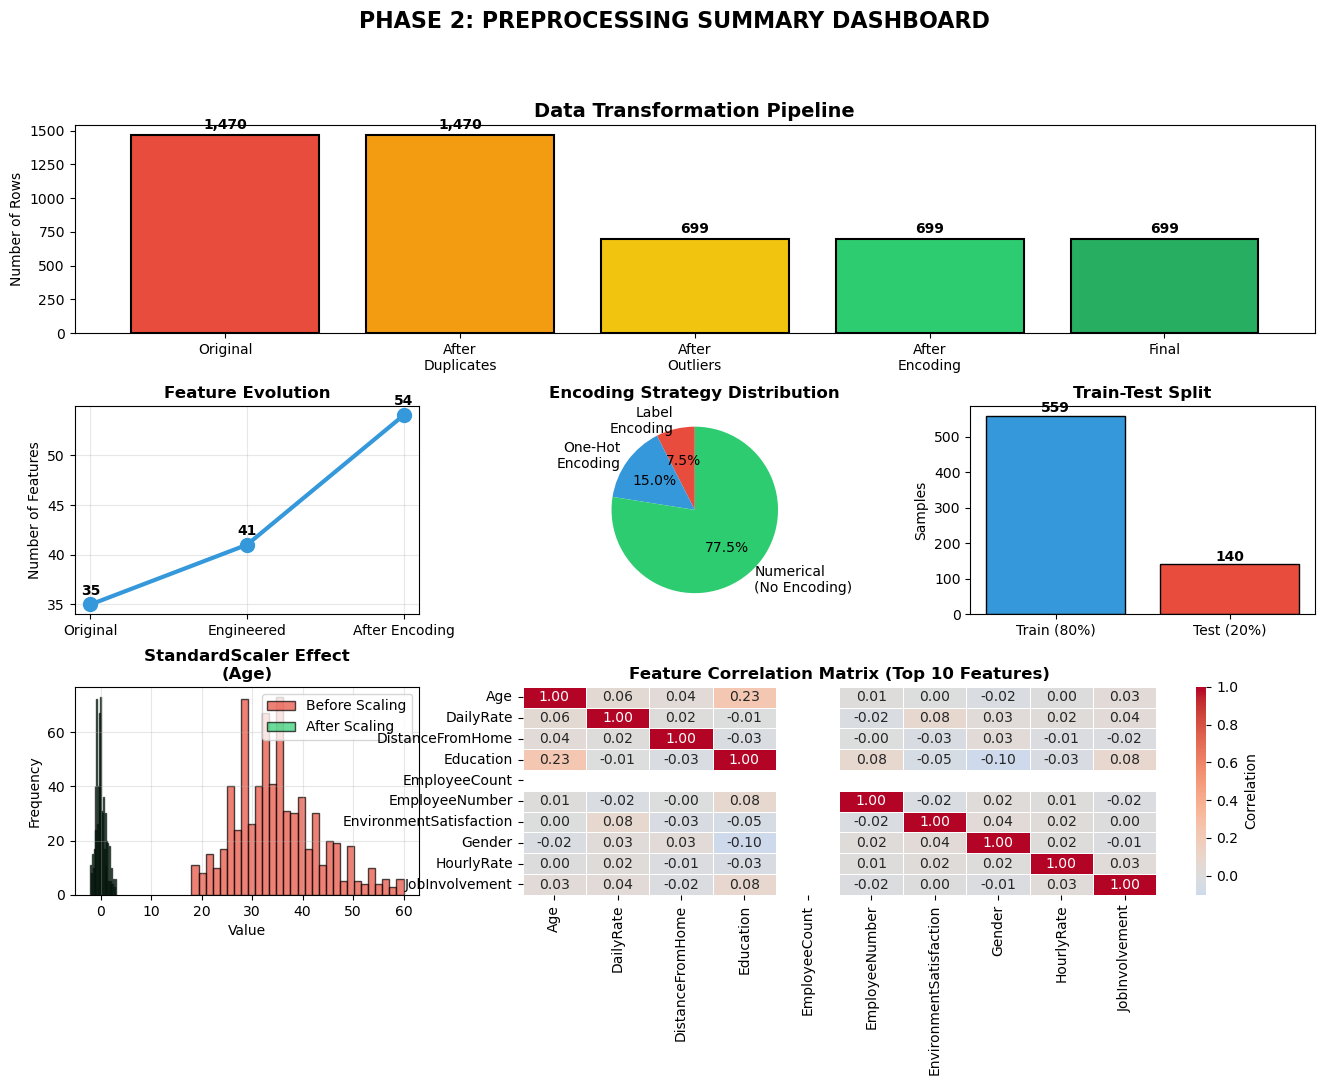

✅ Visualization saved: 'phase2_preprocessing_summary.png'

✅ PHASE 2 COMPLETE - PREPROCESSING SUMMARY

📊 DATA QUALITY IMPROVEMENTS:
   • Duplicates removed: 0
   • Outliers removed: 771 rows
   • Missing values: Handled (0 remaining)

🔧 FEATURE ENGINEERING:
   • Original features: 35
   • New features created: 6
   • Final features: 53

🏷️ ENCODING APPLIED:
   • Label Encoding: 3 columns
   • One-Hot Encoding: 6 columns

📏 SCALING METHODS:
   • StandardScaler: ✅ (Used for modeling)
   • MinMaxScaler: ✅ (Alternative available)

📂 TRAIN-TEST SPLIT:
   • Training: 559 samples (80%)
   • Testing: 140 samples (20%)
   • Stratified: Yes (balanced classes)

💾 FILES SAVED:
   • X_train.csv, X_test.csv
   • y_train.csv, y_test.csv
   • hr_processed.csv

🚀 Ready for PHASE 3: MODELING


In [1]:
# ====================================
# FINAL SUMMARY
# ====================================
print("\n" + "="*70)
print("✅ PHASE 2 COMPLETE - PREPROCESSING SUMMARY")
print("="*70)
print(f"""
📊 DATA QUALITY IMPROVEMENTS:
   • Duplicates removed: {duplicates}
   • Outliers removed: {removed_rows} rows
   • Missing values: Handled (0 remaining)

🔧 FEATURE ENGINEERING:
   • Original features: {df.shape[1]}
   • New features created: {df_engineered.shape[1] - df.shape[1]}
   • Final features: {X.shape[1]}

🏷️ ENCODING APPLIED:
   • Label Encoding: {len(label_encoded_cols)} columns
   • One-Hot Encoding: {len(onehot_encoded_cols)} columns

📏 SCALING METHODS:
   • StandardScaler: ✅ (Used for modeling)
   • MinMaxScaler: ✅ (Alternative available)

📂 TRAIN-TEST SPLIT:
   • Training: {len(X_train)} samples (80%)
   • Testing: {len(X_test)} samples (20%)
   • Stratified: Yes (balanced classes)

💾 FILES SAVED:
   • X_train.csv, X_test.csv
   • y_train.csv, y_test.csv
   • hr_processed.csv
""")
print("="*70)
print("🚀 Ready for PHASE 3: MODELING")
print("="*70)